# Sistema Inteligente de Gerenciamento de Tráfego e Capacidade
**Projeto de Mineração de Dados — Engenharia de Software, 6º período · Tema 5 · Kauan de Oliveira Machado e Carlos Leopoldo Moscardi**

Notebook principal, organizado nas seis fases do **CRISP-DM**. A lógica fica nos módulos de `src/`; o notebook
orquestra e mostra os resultados. Assim notebook, API, dashboard e testes usam exatamente o mesmo código.

**Como executar:** *Run → Restart Kernel and Run All Cells*. Tempo aproximado: 3 a 5 minutos
(a leitura de ~3 milhões de linhas de log e a busca de hiperparâmetros são as partes mais demoradas).

In [1]:
%matplotlib inline
import sys, json, sqlite3, subprocess
from pathlib import Path

# Descobre a raiz do projeto, esteja o notebook aberto em notebooks/ ou na raiz
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config, data, capacity, viz, inference
from src.features import FEATURES, LAGS
from src.pipeline import (etapa_entendimento, etapa_preparacao, divisao_temporal, etapa_modelagem,
                          etapa_avaliacao, etapa_clustering, etapa_implantacao, gerar_figuras)

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)
config.garantir_pastas()
print("Raiz do projeto:", ROOT)
print("Arquivos em data/raw:", [p.name for p in config.DATA_RAW_DIR.iterdir()])

Raiz do projeto: /home/claude/work/proj
Arquivos em data/raw: ['nasa_access_log_1995.zip', 'LEIA-ME.txt']


## 1. Entendimento do negócio

**Problema.** Aplicações web sofrem picos de requisições que aumentam a latência, causam indisponibilidade e degradam
a experiência do usuário. Escalar a infraestrutura leva tempo, então é preciso **saber antes** que o pico vai acontecer.

**Pergunta de mineração.** Com os logs HTTP do servidor, é possível prever quantas requisições chegarão
**daqui a 1 hora** (em janelas de 15 minutos) e classificar o risco de saturação em BAIXO, MÉDIO ou ALTO?

**Por que 1 hora de antecedência.** É um prazo realista para acionar a escalabilidade (subir instâncias, ativar cache,
avisar a equipe). Prever os próximos 15 minutos seria fácil demais e pouco útil na prática.

**Dados.** Logs reais de todas as requisições HTTP ao servidor web do Kennedy Space Center da NASA em julho e agosto de
1995 (Internet Traffic Archive / Kaggle).

**Critérios de sucesso.**
1. Superar as três *baselines* de série temporal (persistência, sazonal diária e sazonal semanal) no RMSE e no MAPE.
2. R² acima de 0,80 no período de teste, prevendo com 1 hora de antecedência.
3. Precision acima de 0,80 na classe de risco ALTO (poucos alarmes falsos), porque cada alerta dispara o custo de escalar.

## 2. Entendimento dos dados

In [2]:
bruto, qualidade = etapa_entendimento()
print(f"Arquivos: {qualidade['arquivos']}  |  MD5: {qualidade['hash_md5']}")
display(bruto.head())
bruto.dtypes.to_frame("tipo").T

Arquivos: ['nasa_access_log_1995.zip']  |  MD5: 12c1e8e77c96355dfd24093d981f7bbe


,host,data_hora,metodo,url,status,bytes
0,199.72.81.55,1995-07-01 00:00:01,GET,/history/apollo/,200,6245
1,unicomp6.unicomp.net,1995-07-01 00:00:06,GET,/shuttle/countdown/,200,3985
2,199.120.110.21,1995-07-01 00:00:09,GET,/shuttle/missions/sts-73/mission-sts-73.html,200,4085
3,199.120.110.21,1995-07-01 00:00:11,GET,/shuttle/missions/sts-73/sts-73-patch-small.gif,200,4179
4,burger.letters.com,1995-07-01 00:00:11,GET,/shuttle/countdown/liftoff.html,304,0


,host,data_hora,metodo,url,status,bytes
tipo,string,datetime64[us],category,string,int16,int64


### Dicionário de dados
| Campo | Descrição | Uso |
|---|---|---|
| `host` | cliente que fez a requisição (nome ou IP) | clientes distintos por intervalo; perfis de clientes |
| `data_hora` | instante da requisição (convertido de Unix/UTC para o horário local da Flórida, -04:00) | série temporal |
| `metodo` | GET, HEAD ou POST | qualidade |
| `url` | recurso solicitado | qualidade |
| `status` | código de resposta HTTP | taxa de erro (4xx/5xx) |
| `bytes` | tamanho da resposta | volume transferido |

In [3]:
resumo = {k: v for k, v in qualidade.items() if not isinstance(v, (dict, list))}
display(pd.Series(resumo, name="valor").to_frame())
display(pd.DataFrame([qualidade["status_http"]], index=["requisições"]).rename(columns=str))
pd.DataFrame(qualidade["lacunas"])

,valor
registros,2965561
total_oficial,3461612
percentual_do_oficial,85.70
periodo_inicio,1995-07-01 00:00:01
periodo_fim,1995-08-31 23:59:53
hosts_distintos,135268
urls_distintas,365
linhas_identicas,1087
percentual_erros_4xx_5xx,0.13
respostas_sem_corpo_bytes_0,281255


,200,302,304,404,501
requisições,2696600,6912,258161,3858,30


,inicio,fim,horas
0,1995-07-28 13:45:00,1995-08-01 00:00:00,82.25
1,1995-08-01 15:00:00,1995-08-03 04:30:00,37.50


**Achados de qualidade:**
- **Queda real do servidor:** entre 01/08 15h e 03/08 04h30 não há registros. A documentação oficial explica que o
  servidor foi desligado por causa do **furacão Erin**.
- **Lacuna de 28/07 a 31/07:** não é citada na documentação oficial e provavelmente foi perdida na versão do Kaggle.
- **Volume menor que o oficial:** o arquivo tem cerca de 86% das 3.461.612 requisições documentadas; o Kaggle removeu
  linhas no pré-processamento (só restaram os códigos 200, 302, 304, 404 e 501).
- **Fuso horário:** o campo `time` está em Unix/UTC. Convertido para -04:00, o período bate exatamente com o oficial
  (01/07 00:00 a 31/08 23:59). Sem essa conversão, o pico diário ficaria deslocado em 4 horas.
- **Linhas idênticas:** algumas requisições repetidas no mesmo segundo. Foram **mantidas**, porque em log de servidor cada
  linha é um acesso que consumiu recurso (ex.: o usuário recarregou a página).
- **304 com 0 bytes** é esperado: "não modificado", o navegador usou o cache.

In [4]:
# Dias com mais requisições: 13/07 foi o lançamento do ônibus espacial STS-70
por_dia = bruto.set_index("data_hora").resample("D").size()
display(por_dia.sort_values(ascending=False).head(5).to_frame("requisições no dia"))

,requisições no dia
data_hora,
1995-07-13,118606
1995-07-06,86302
1995-07-05,80241
1995-07-12,79776
1995-08-31,79682


## 3. Preparação dos dados
Decisões aplicadas em `src/data.py` e `src/features.py`:
1. **ETL:** 3 milhões de linhas de log viram uma série em intervalos de 15 minutos com `requisicoes`, `hosts_unicos`
   (aproximação de usuários simultâneos), `taxa_erro` e `mb_transferidos`;
2. **lacunas** (1 hora ou mais sem nenhuma requisição) viram `NaN`, e não zero: o servidor estava fora do ar, isso não é
   demanda. Um intervalo isolado com zero é mantido (demanda baixa real);
3. **calendário:** hora, dia da semana, fim de semana, feriado (04/07) e codificação seno/cosseno;
4. **histórico disponível 1 hora antes do alvo:** requisições de 1h, 1h15, 1h30 e 1h45 atrás, mesmo horário de ontem e da
   semana passada, médias móveis de 1h e 24h, desvio de 24h e clientes, erros e MB de 1h atrás;
5. remoção dos intervalos cujo histórico cai em uma lacuna;
6. divisão **temporal** 80/20, sem embaralhar.

In [5]:
grade, tabela = etapa_preparacao(bruto)
print(f"Log: {len(bruto):,} linhas -> série de 15 min: {len(grade):,} intervalos "
      f"({int(grade['requisicoes'].isna().sum())} em lacunas) -> tabela de modelagem: {len(tabela):,} x {len(FEATURES)} atributos")
display(grade.dropna().head())
tabela.head()

Log: 2,965,561 linhas -> série de 15 min: 5,952 intervalos (479 em lacunas) -> tabela de modelagem: 4,163 x 20 atributos


,requisicoes,hosts_unicos,taxa_erro,mb_transferidos,fora_do_ar
data_hora,,,,,
1995-07-01 00:00:00,685.00,111.00,0.29,10.70,0
1995-07-01 00:15:00,819.00,130.00,0.37,14.32,0
1995-07-01 00:30:00,844.00,125.00,0.00,15.22,0
1995-07-01 00:45:00,685.00,121.00,0.44,18.74,0
1995-07-01 01:00:00,663.00,112.00,0.15,14.33,0


,hora,dia_semana,fim_de_semana,feriado,hora_sin,hora_cos,dia_sin,dia_cos,req_1h_atras,req_1h15_atras,...,req_1h45_atras,req_24h_atras,req_7d_atras,media_movel_1h,media_movel_24h,desvio_movel_24h,hosts_1h_atras,taxa_erro_1h_atras,mb_1h_atras,requisicoes
data_hora,,,,,,,,,,,,,,,,,,,,,
1995-07-08 00:00:00,0,5,1,0,0.00,1.00,-0.97,-0.22,424.00,497.00,...,561.00,658.00,685.00,506.50,787.31,403.00,67.00,0.47,10.86,469.00
1995-07-08 00:15:00,0,5,1,0,0.07,1.00,-0.97,-0.22,542.00,424.00,...,544.00,653.00,819.00,501.75,784.56,403.77,86.00,0.00,10.82,514.00
1995-07-08 00:30:00,0,5,1,0,0.13,0.99,-0.97,-0.22,514.00,542.00,...,497.00,535.00,844.00,494.25,779.33,403.99,62.00,0.00,9.45,525.00
1995-07-08 00:45:00,0,5,1,0,0.20,0.98,-0.97,-0.22,564.00,514.00,...,424.00,479.00,685.00,511.00,777.49,404.57,73.00,0.00,15.55,526.00
1995-07-08 01:00:00,1,5,1,0,0.26,0.97,-0.97,-0.22,469.00,564.00,...,542.00,451.00,663.00,522.25,775.52,405.62,68.00,0.85,9.86,510.00


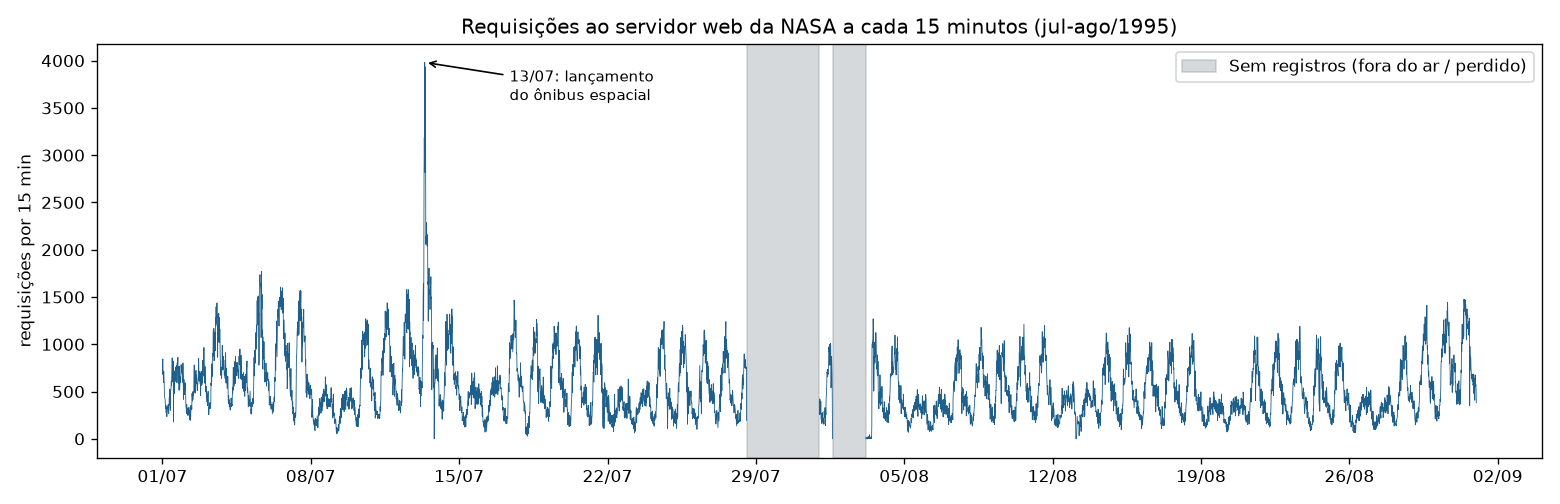

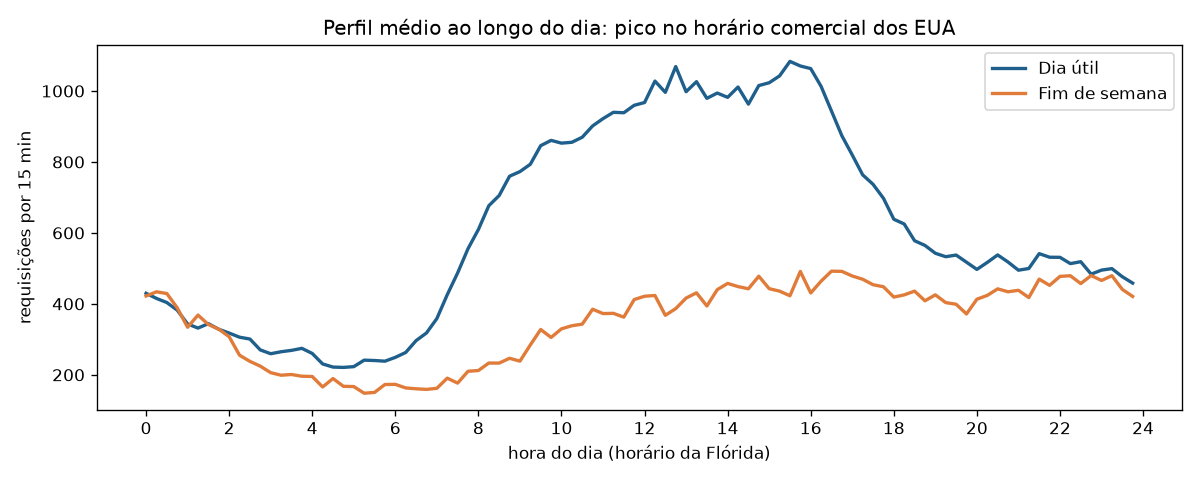

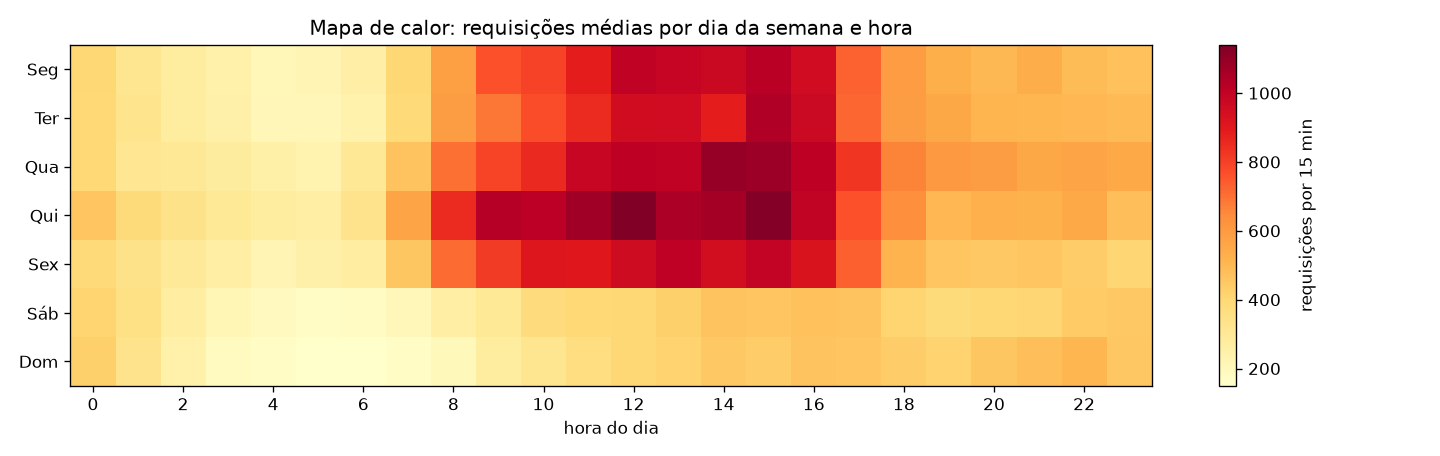

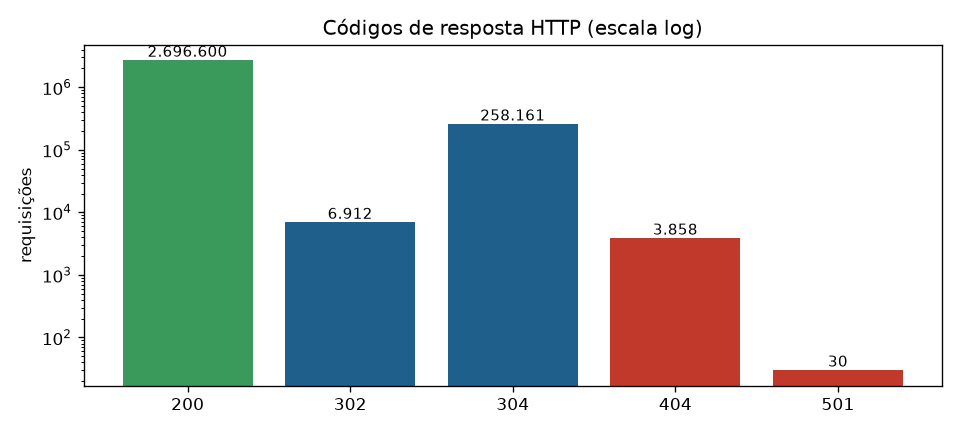

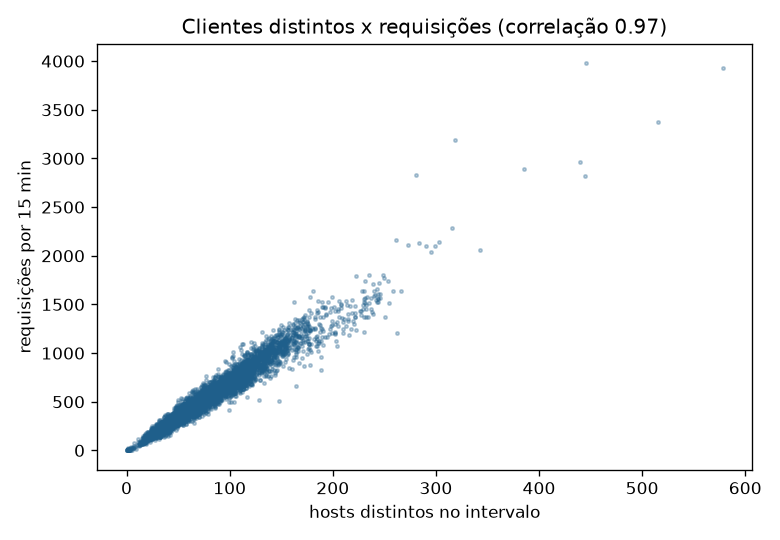

In [6]:
# Análise exploratória sobre a série tratada
for f in [viz.serie_temporal(grade, qualidade["lacunas"]), viz.perfil_horario(grade), viz.heatmap_hora_dia(grade),
          viz.status_http(qualidade), viz.usuarios_vs_requisicoes(grade)]:
    display(Image(f))

**Leitura da EDA.** O tráfego segue o horário comercial dos EUA: sobe a partir das 6h, tem o pico entre 10h e 16h e cai
à noite. Nos fins de semana o volume é cerca de metade. O número de clientes distintos acompanha fortemente o número de
requisições, por isso é um bom sinal antecipado de carga. O dia 13/07 mostra um pico excepcional de demanda: exatamente
o tipo de evento que um sistema de capacidade precisa antecipar.

In [7]:
# Prova de que os atributos usam apenas dados disponíveis 1 hora antes do alvo
alvo = tabela.index[1000]
pd.DataFrame({
    "valor na tabela": [tabela.loc[alvo, nome] for nome in LAGS],
    "valor real na série": [grade.loc[alvo - p * pd.Timedelta("15min"), "requisicoes"] for p in LAGS.values()],
    "instante": [alvo - p * pd.Timedelta("15min") for p in LAGS.values()],
}, index=list(LAGS))

,valor na tabela,valor real na série,instante
req_1h_atras,656.00,656.00,1995-07-18 09:00:00
req_1h15_atras,672.00,672.00,1995-07-18 08:45:00
req_1h30_atras,588.00,588.00,1995-07-18 08:30:00
req_1h45_atras,385.00,385.00,1995-07-18 08:15:00
req_24h_atras,901.00,901.00,1995-07-17 10:00:00
req_7d_atras,903.00,903.00,1995-07-11 10:00:00


In [8]:
treino, teste = divisao_temporal(tabela)
capacidade_ref = capacity.calcular_capacidade(treino[config.TARGET])
print(f"Treino: {treino.index.min()} até {treino.index.max()}  ({len(treino):,} intervalos)")
print(f"Teste : {teste.index.min()} até {teste.index.max()}  ({len(teste):,} intervalos)")
print(f"Capacidade de referência (P95 do treino): {capacidade_ref:,.0f} req/15 min = {capacidade_ref/900:.2f} req/s")
print(f"Limiar MÉDIO (70%): {0.7*capacidade_ref:,.0f} | Limiar ALTO (90%): {0.9*capacidade_ref:,.0f}")

Treino: 1995-07-08 00:00:00 até 1995-08-23 07:30:00  (3,330 intervalos)
Teste : 1995-08-23 07:45:00 até 1995-08-31 23:45:00  (833 intervalos)
Capacidade de referência (P95 do treino): 1,107 req/15 min = 1.23 req/s
Limiar MÉDIO (70%): 775 | Limiar ALTO (90%): 996


## 4. Modelagem
| Modelo | Papel |
|---|---|
| Baseline persistência | série temporal ingênua: "daqui a 1h será igual a agora" |
| Baseline sazonal diária | série temporal ingênua: "igual ao mesmo horário de ontem" |
| Baseline sazonal semanal | série temporal ingênua: "igual ao mesmo horário da semana passada" |
| ARIMA + Fourier | série temporal clássica: ARIMA com a sazonalidade diária e semanal descrita por senos e cossenos |
| Regressão Linear | referência interpretável |
| Random Forest | conjunto de árvores, capta relações não lineares |
| Gradient Boosting | árvores sequenciais que corrigem os erros anteriores |
| Rede Neural (MLP) | perceptron multicamadas, algoritmo sugerido para o tema |

Os hiperparâmetros são escolhidos com `GridSearchCV` + `TimeSeriesSplit` (3 dobras em ordem cronológica), **apenas no
treino**. O modelo final é o de menor RMSE nessa validação; o teste é usado uma única vez. Sementes, grades de
hiperparâmetros e regras de capacidade ficam em `params.yaml`.

**Por que ARIMA + Fourier, e não SARIMA.** Com intervalos de 15 minutos, o ciclo diário tem 96 passos e o semanal 672.
Um SARIMA com período 96 fica lento demais para ajustar. A solução usual (regressão harmônica dinâmica) descreve a
sazonalidade com termos de Fourier e deixa o ARIMA modelar a autocorrelação de curto prazo. A previsão para cada
intervalo usa só o que se sabia 1 hora antes (filtro de Kalman projetado 4 passos à frente).

In [9]:
modelos, cv, melhor = etapa_modelagem(treino)
print("\nModelo escolhido pela validação cruzada:", melhor)
cv.sort_values("RMSE_cv_media")

  Baseline: persistência (agora)               RMSE CV =  148.0 ±  11.9  (1 config.,  0.0s)
  Baseline: sazonal diário (ontem)             RMSE CV =  219.1 ±  30.6  (1 config.,  0.0s)
  Baseline: sazonal semanal (semana passada)   RMSE CV =  226.2 ± 100.0  (1 config.,  0.0s)


  ARIMA + Fourier                              RMSE CV =  122.2 ±  15.8  (4 config., 24.4s)
  Regressão Linear                             RMSE CV =  126.7 ±  18.1  (1 config.,  0.0s)


  Random Forest                                RMSE CV =  109.8 ±  15.6  (8 config., 22.6s)


  Gradient Boosting                            RMSE CV =  110.0 ±  12.8  (8 config., 189.7s)


  Rede Neural (MLP)                            RMSE CV =  126.7 ±  28.3  (6 config.,  9.8s)

Modelo escolhido pela validação cruzada: Random Forest


,modelo,RMSE_cv_media,RMSE_cv_desvio,MAE_cv_media,MAE_cv_desvio,combinacoes_testadas,melhores_parametros,tempo_s
5,Random Forest,109.79,15.64,81.43,11.49,8,"{""max_depth"": ""None"", ""max_features"": ""0.5"", ""min_samples_leaf"": ""5""}",22.61
6,Gradient Boosting,109.95,12.79,82.32,10.03,8,"{""learning_rate"": ""0.03"", ""max_depth"": ""None"", ""min_samples_leaf"": ""50""}",189.72
3,ARIMA + Fourier,122.23,15.75,93.05,12.51,4,"{""k_diario"": ""6"", ""k_semanal"": ""3"", ""p"": ""2"", ""q"": ""1""}",24.40
4,Regressão Linear,126.69,18.11,96.61,14.36,1,{},0.04
7,Rede Neural (MLP),126.75,28.33,93.98,20.56,6,"{""alpha"": ""0.1"", ""hidden_layer_sizes"": ""(64, 32)""}",9.76
0,Baseline: persistência (agora),148.04,11.92,111.25,8.59,1,{},0.04
1,Baseline: sazonal diário (ontem),219.05,30.59,149.70,22.50,1,{},0.01
2,Baseline: sazonal semanal (semana passada),226.23,100.00,142.21,45.08,1,{},0.01


## 5. Avaliação

In [10]:
metricas, previsoes, cm, relatorio_risco, importancia = etapa_avaliacao(modelos, teste, melhor, capacidade_ref)
metricas

,modelo,MAE,RMSE,MAPE,R2
0,Random Forest,81.15,111.85,19.08,0.88
1,ARIMA + Fourier,89.83,122.47,21.00,0.85
2,Regressão Linear,94.31,128.25,21.02,0.84
3,Gradient Boosting,90.91,135.08,19.77,0.82
4,Rede Neural (MLP),92.90,135.52,19.59,0.82
5,Baseline: persistência (agora),116.59,158.81,25.38,0.75
6,Baseline: sazonal semanal (semana passada),139.00,204.03,27.34,0.59
7,Baseline: sazonal diário (ontem),156.70,218.56,35.89,0.53


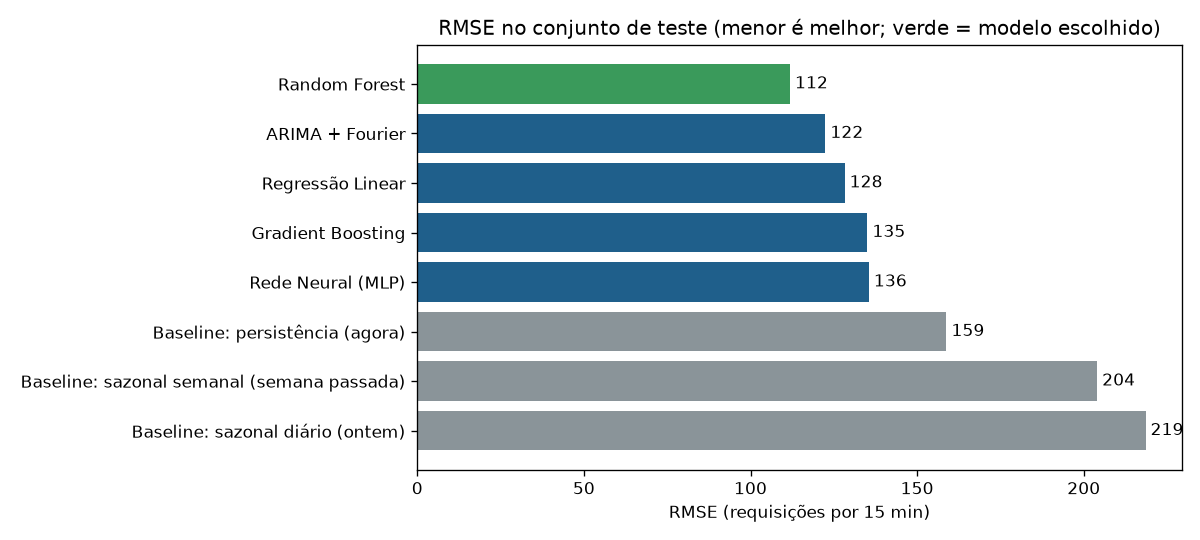

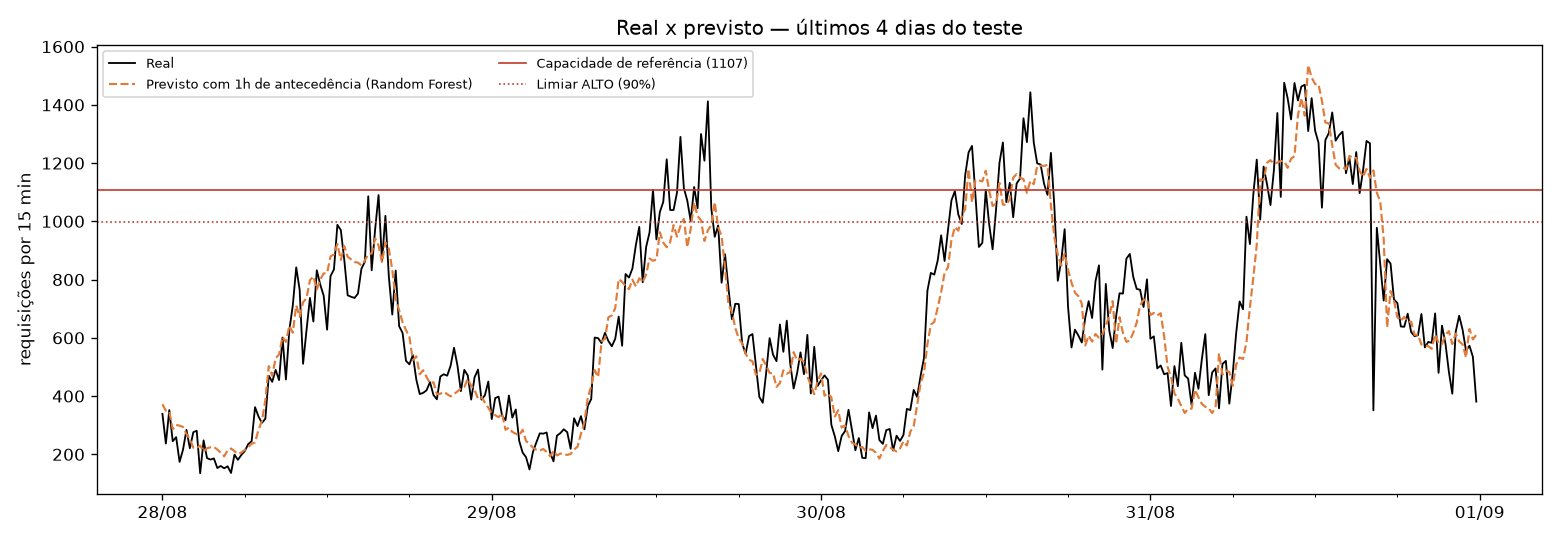

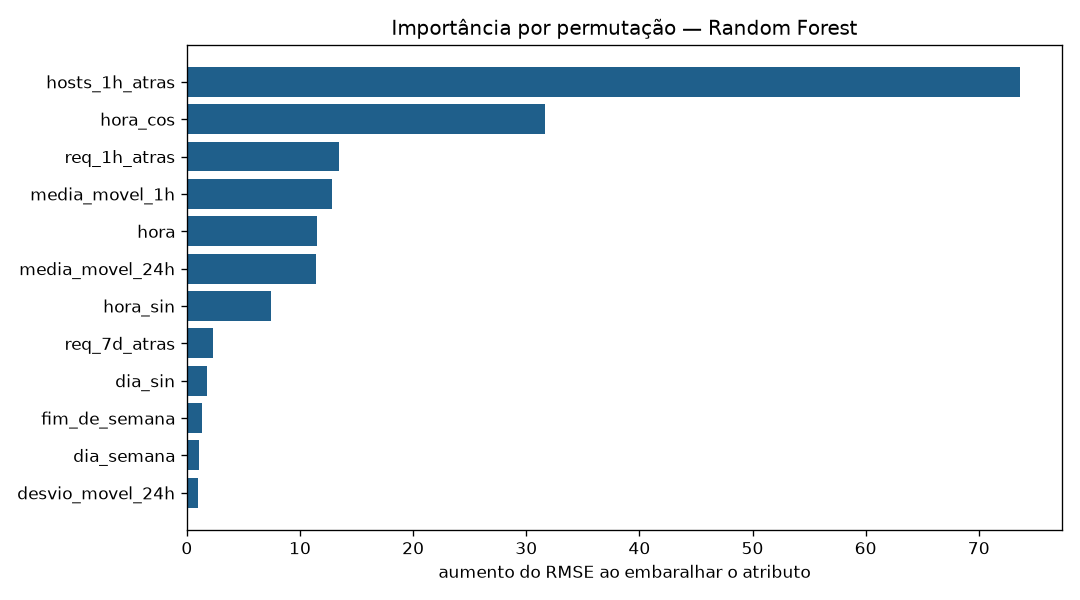

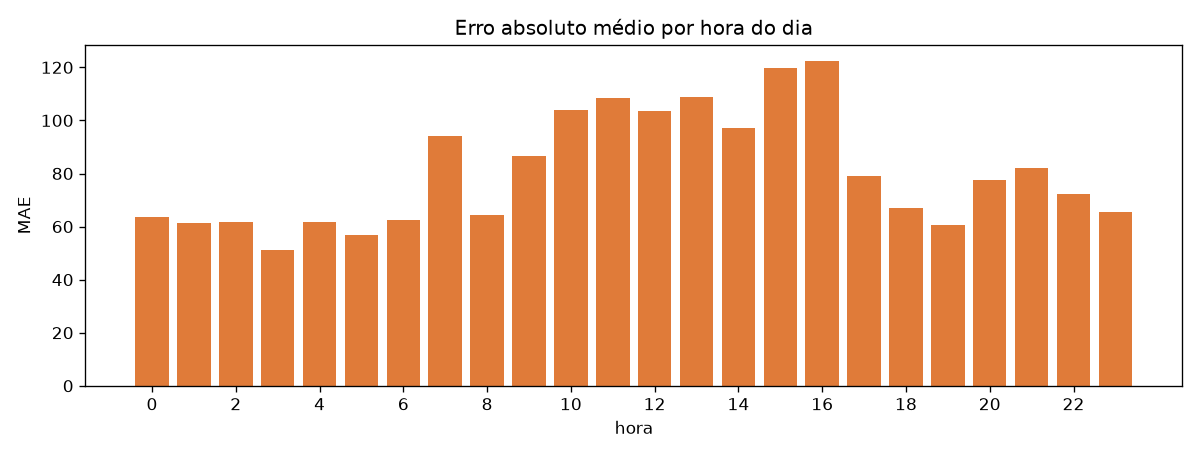

In [11]:
clusters = etapa_clustering(grade, bruto)
figs = gerar_figuras(grade, qualidade, metricas, melhor, previsoes, capacidade_ref, importancia, cm, clusters)
for f in figs[5:9]:
    display(Image(f))

**Leitura.** MAE é o erro médio em requisições por 15 min; RMSE penaliza erros grandes (os que importam perto dos picos);
MAPE é o erro médio em porcentagem do valor real; R² mede quanto da variação é explicada. Todos os modelos superam as
três baselines. O ARIMA + Fourier, modelo clássico de série temporal, fica em segundo no RMSE: a sazonalidade explica
boa parte da carga, e os modelos de árvores ganham ao usar também os clientes distintos e as médias móveis. Os atributos mais
importantes são o número de **clientes distintos agora** e a **hora do dia**.

Random Forest e Gradient Boosting ficaram muito próximos na validação cruzada (diferença menor que o desvio entre as
dobras). O modelo implantado é sempre o de menor RMSE na validação, escolhido automaticamente pelo código; o teste só
confirma o resultado. Com versões diferentes das bibliotecas o desempate pode mudar, e o model card registra qual foi o
escolhido. A última semana do teste (29 a 31/08) tem um crescimento de acesso acima do padrão do treino, o que explica
parte do erro.

No risco, o modelo acerta quase sempre quando emite ALTO (precision alta), mas deixa passar parte dos picos (recall
menor), porque tende a subestimar os maiores valores. Na prática isso se ajusta baixando o limiar de alerta: mais picos
detectados em troca de mais alarmes falsos.

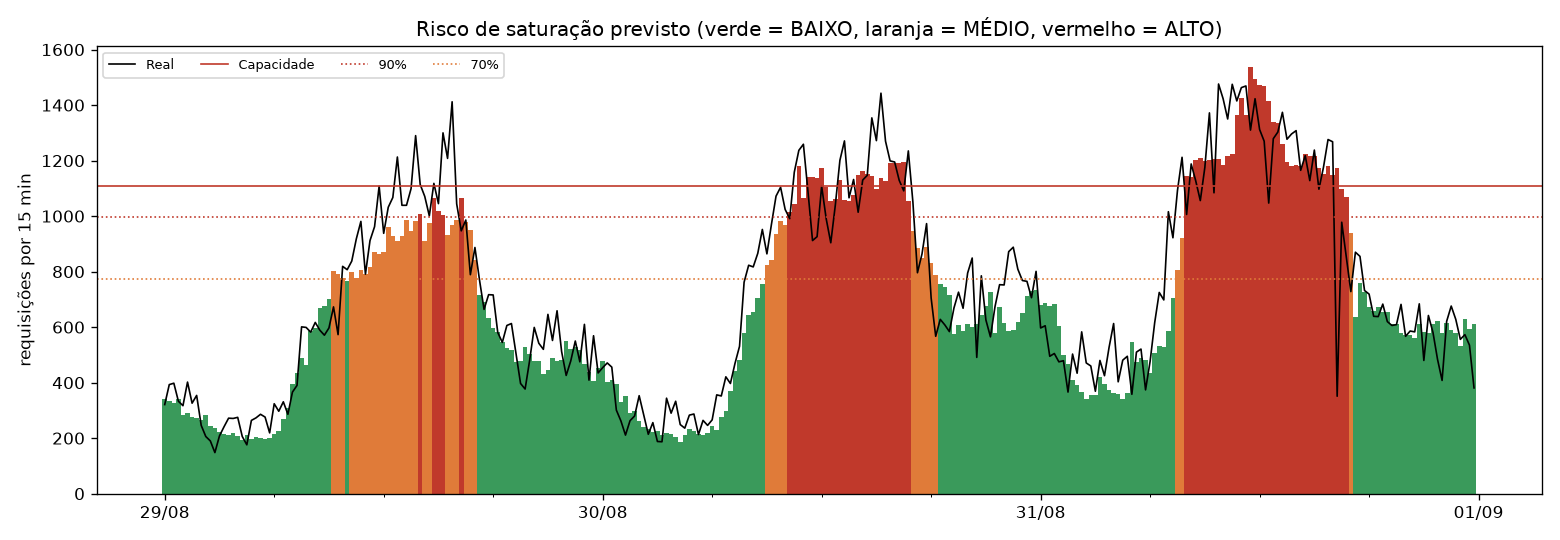

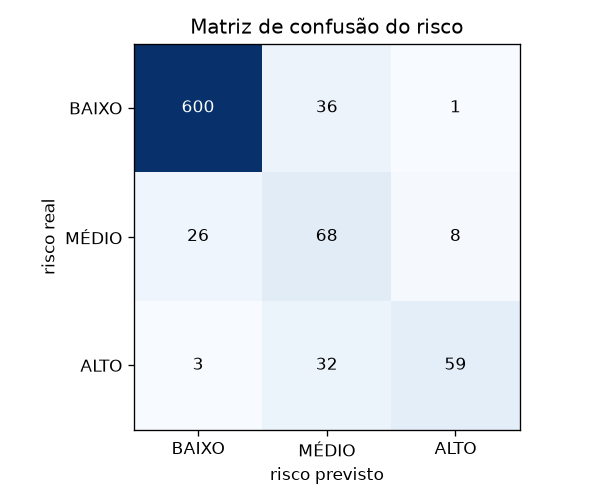

,precision,recall,f1-score,support
BAIXO,0.95,0.94,0.95,637.00
MÉDIO,0.50,0.67,0.57,102.00
ALTO,0.87,0.63,0.73,94.00
macro avg,0.77,0.75,0.75,833.00


In [12]:
# Risco de saturação: classificação derivada da previsão
for f in figs[9:11]:
    display(Image(f))
pd.DataFrame(relatorio_risco).T.loc[capacity.NIVEIS + ["macro avg"], ["precision", "recall", "f1-score", "support"]]

### Clustering (K-Means): perfis diários e perfis de clientes

Perfis diários: k = 3


,k,silhouette,davies_bouldin,inercia
0,2,0.49,0.67,"675,302,217.34"
1,3,0.52,0.47,"372,524,167.74"
2,4,0.52,0.57,"188,328,549.16"
3,5,0.50,0.59,"149,783,424.20"
4,6,0.44,0.80,"126,319,254.83"


Perfis de clientes (103,986 clientes com 5 ou mais requisições): k = 3


,k,silhouette,davies_bouldin,inercia
0,2,0.28,1.56,"498,462.34"
1,3,0.30,1.21,"417,880.69"
2,4,0.27,1.16,"346,529.61"
3,5,0.30,1.03,"273,945.33"
4,6,0.30,0.99,"231,985.75"


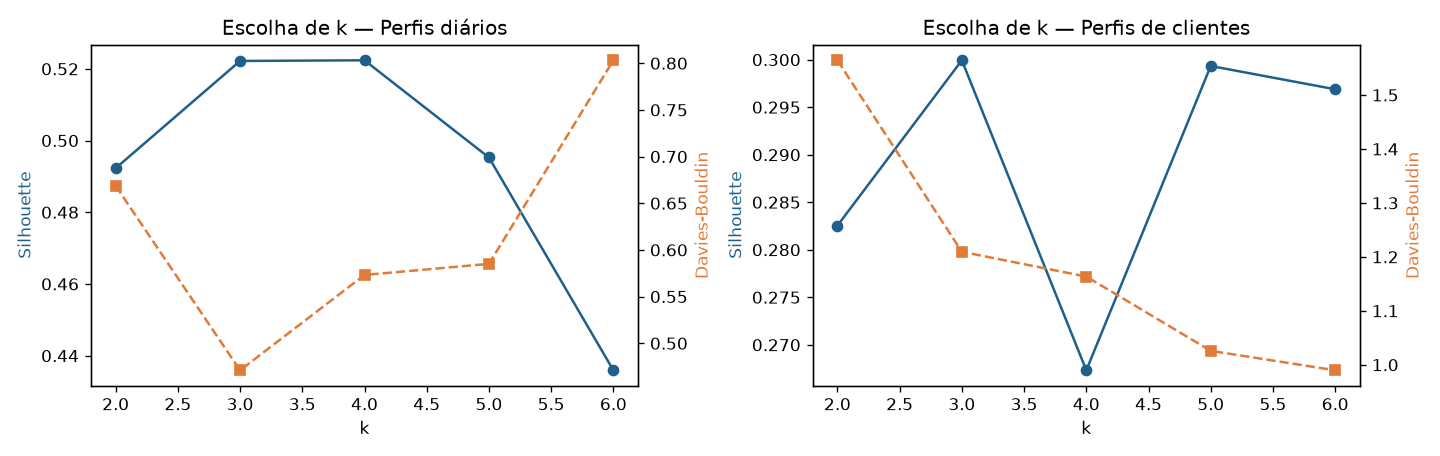

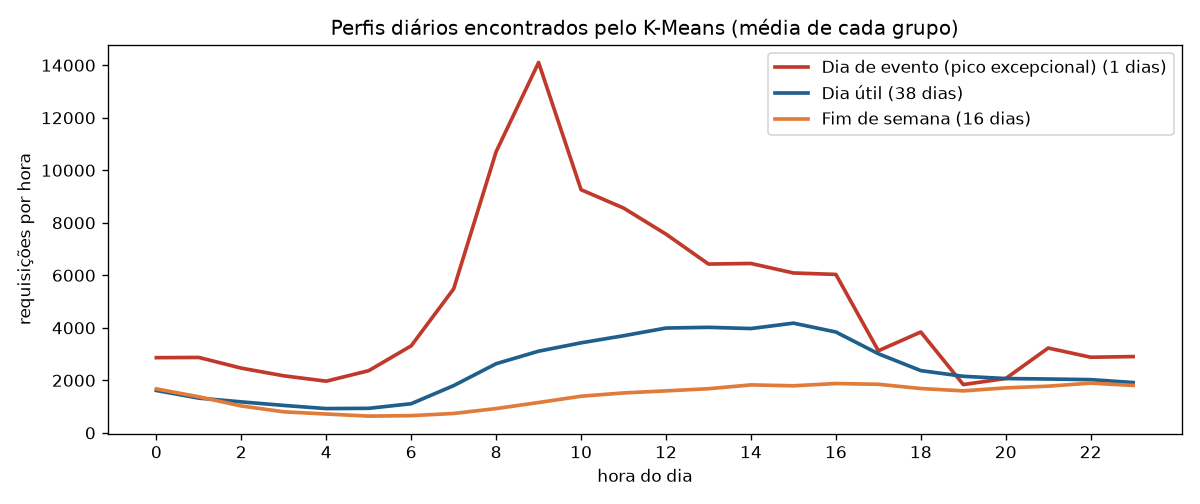

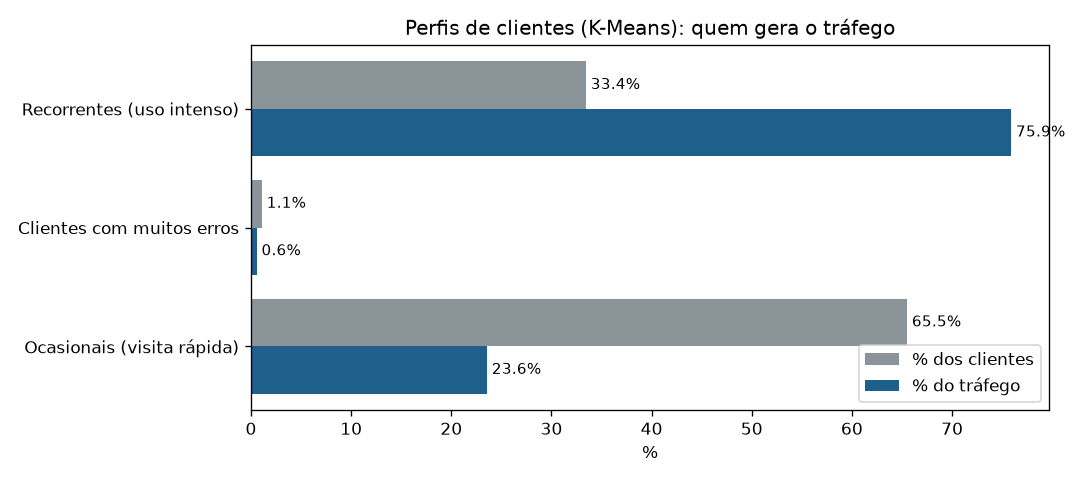

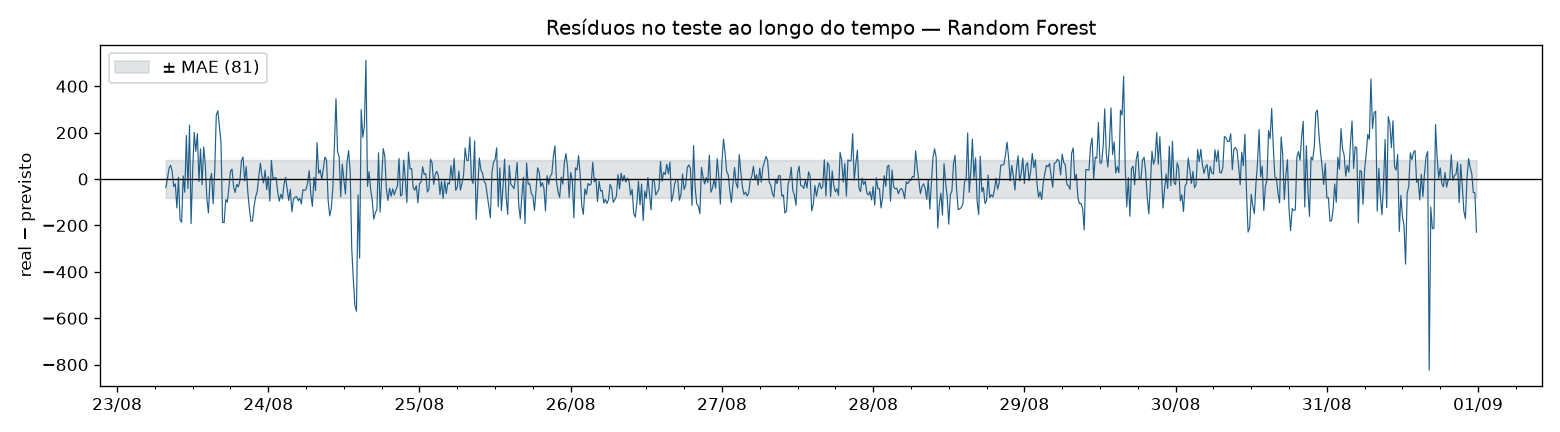

,dias,req_por_dia
perfil,,
Dia de evento (pico excepcional),1,"118,606.00"
Dia útil,38,"58,406.50"
Fim de semana,16,"33,728.75"


,perfil,hosts,req_mediana,horas_ativas_mediana,kb_por_req,taxa_erro_media,pct_cache_304,req_total,pct_do_trafego,pct_dos_hosts
0,Recorrentes (uso intenso),34767,32.00,3.00,11.91,0.06,7.64,2189466,75.89,33.43
1,Clientes com muitos erros,1113,12.00,1.00,5.68,15.79,7.56,16016,0.56,1.07
2,Ocasionais (visita rápida),68106,9.00,1.00,7.19,0.01,3.90,679603,23.56,65.50


In [13]:
print(f"Perfis diários: k = {clusters['k_dias']}")
display(clusters["aval_dias"])
print(f"Perfis de clientes ({clusters['n_hosts']:,} clientes com 5 ou mais requisições): k = {clusters['k_hosts']}")
display(clusters["aval_hosts"])
for f in figs[11:]:
    display(Image(f))
display(clusters["dias"].groupby("perfil").agg(dias=("cluster", "size"), req_por_dia=("req_dia", "mean")))
clusters["resumo_hosts"]

**Escolha de k.** Pela regra da parcimônia: entre os valores de k com Silhouette a menos de 1% do melhor, fica o menor.

**Leitura.** Os dias se separam em *dia útil*, *fim de semana* e um *dia de evento* (13/07, lançamento do STS-70), que
exigiria uma política de capacidade própria. Nos clientes, um terço dos hosts (os recorrentes) gera cerca de 3/4 do
tráfego, e um grupo pequeno concentra erros 404, típico de links quebrados ou robôs. Seguindo a orientação da base, a
análise fica em padrões gerais de tráfego, sem identificar clientes individualmente.

## 6. Implantação
Salva o modelo (`models/modelo_trafego.joblib`), o *model card* com versão, hiperparâmetros, hash dos dados e métricas
(`models/model_card.json`), as saídas em `outputs/` e o banco SQLite (`outputs/trafego.db`). Se o MLflow estiver
instalado, cada modelo vira um *run* com parâmetros e métricas, e o escolhido é registrado no Model Registry
(`previsao-trafego-1h`). O número do run fica no model card.

In [14]:
card = etapa_implantacao(modelos, melhor, capacidade_ref, metricas, cv, previsoes, grade, qualidade, clusters,
                         relatorio_risco, importancia, treino, teste)
print(json.dumps({k: card[k] for k in ["versao", "modelo", "melhores_parametros", "metricas_teste",
                                       "capacidade_referencia_req_15min", "risco_alto"]}, indent=2, ensure_ascii=False))

Registered model 'previsao-trafego-1h' already exists. Creating a new version of this model...
Created version '3' of model 'previsao-trafego-1h'.


  MLflow: 8 runs registrados; modelo 'previsao-trafego-1h' versão 3


{
  "versao": "20261118-135132",
  "modelo": "Random Forest",
  "melhores_parametros": {
    "max_depth": "None",
    "max_features": "0.5",
    "min_samples_leaf": "5"
  },
  "metricas_teste": {
    "MAE": 81.1491,
    "RMSE": 111.847,
    "MAPE": 19.0798,
    "R2": 0.8766
  },
  "capacidade_referencia_req_15min": 1107.0,
  "risco_alto": {
    "precision": 0.868,
    "recall": 0.628,
    "f1-score": 0.728,
    "support": 94.0
  }
}


In [15]:
with sqlite3.connect(config.DB_PATH) as con:
    print(pd.read_sql("SELECT name AS tabela FROM sqlite_master WHERE type='table'", con)["tabela"].tolist())
    display(pd.read_sql("SELECT risco_previsto, COUNT(*)/4.0 AS horas FROM previsoes_teste GROUP BY risco_previsto", con))
    display(pd.read_sql("SELECT executado_em, melhor_modelo, hash_dados FROM execucoes ORDER BY executado_em DESC LIMIT 3", con))

['execucoes', 'requisicoes_15min', 'previsoes_teste', 'metricas', 'validacao_cruzada', 'clusters_diarios', 'clusters_clientes']


,risco_previsto,horas
0,ALTO,17.00
1,BAIXO,157.25
2,MÉDIO,34.00


,executado_em,melhor_modelo,hash_dados
0,2026-11-18T13:51:38,Random Forest,12c1e8e77c96355dfd24093d981f7bbe
1,2026-11-18T13:46:08,Random Forest,12c1e8e77c96355dfd24093d981f7bbe
2,2026-11-18T13:43:23,Random Forest,12c1e8e77c96355dfd24093d981f7bbe


In [16]:
# Inferência: o mesmo código usado pela API
inference.carregar_modelo.cache_clear()
pd.DataFrame([inference.prever_pelo_historico(t) for t in
              ["1995-08-30 04:00", "1995-08-30 09:00", "1995-08-30 13:00", "1995-08-31 11:00"]])

,previsao_para,gerada_em,requisicoes_agora,clientes_agora,volume_previsto,capacidade_referencia,capacidade_disponivel,utilizacao_percentual,risco_saturacao,volume_previsto_req_s,modelo,versao_modelo,volume_real,risco_real
0,1995-08-30 04:00:00,1995-08-30 03:00:00,188.00,41.00,205.20,"1,107.00",901.80,18.50,BAIXO,0.23,Random Forest,20261118-135132,333.00,BAIXO
1,1995-08-30 09:00:00,1995-08-30 08:00:00,823.00,111.00,823.20,"1,107.00",283.80,74.40,MÉDIO,0.91,Random Forest,20261118-135132,864.00,MÉDIO
2,1995-08-30 13:00:00,1995-08-30 12:00:00,"1,108.00",154.00,"1,131.50","1,107.00",-24.50,102.20,ALTO,1.26,Random Forest,20261118-135132,"1,201.00",ALTO
3,1995-08-31 11:00:00,1995-08-31 10:00:00,"1,423.00",197.00,"1,424.20","1,107.00",-317.20,128.70,ALTO,1.58,Random Forest,20261118-135132,"1,463.00",ALTO


In [17]:
# Testes automatizados, executados com o mesmo Python deste notebook
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-1500:] or r.stderr[-1500:])

..................                                                       [100%]
18 passed in 2.44s



### API e dashboard
Abra um terminal (PowerShell) **na pasta do projeto**, um para cada comando:

```powershell
python -m uvicorn api.app:app --reload                 # documentação em http://127.0.0.1:8000/docs
python -m streamlit run dashboard/streamlit_app.py     # abre em http://localhost:8501
python -m mlflow ui --backend-store-uri sqlite:///mlflow.db   # experimentos em http://127.0.0.1:5000
```

## 7. Conclusão

In [18]:
m = metricas.set_index("modelo")
base = m[m.index.str.startswith("Baseline")]["RMSE"].min()
a = relatorio_risco["ALTO"]
print(f"Modelo implantado: {melhor}")
print(f"  MAE {m.loc[melhor,'MAE']:.1f} | RMSE {m.loc[melhor,'RMSE']:.1f} | MAPE {m.loc[melhor,'MAPE']:.1f}% | R² {m.loc[melhor,'R2']:.3f}")
print(f"  Redução do RMSE em relação à melhor baseline: {100*(1-m.loc[melhor,'RMSE']/base):.0f}%")
print(f"  Risco ALTO: precision {a['precision']:.2f} | recall {a['recall']:.2f} | F1 {a['f1-score']:.2f}")

Modelo implantado: Random Forest
  MAE 81.1 | RMSE 111.8 | MAPE 19.1% | R² 0.877
  Redução do RMSE em relação à melhor baseline: 30%
  Risco ALTO: precision 0.87 | recall 0.63 | F1 0.73


**Limitações.** (1) A base não traz latência, CPU nem memória; a saturação é medida pelo volume de requisições em
relação a uma capacidade de referência (P95), não pela capacidade física do servidor. (2) São apenas dois meses, com
lacunas; o teste cobre a última semana e meia de agosto. (3) Logs de 1995 têm padrão de uso diferente do atual.
(4) Não há ingestão em tempo real nem monitoramento de *data drift*.

**Trabalhos futuros.** Coletar latência e CPU junto com os logs (ex.: Prometheus), previsão multi-horizonte, LSTM,
detecção de eventos (como o lançamento de 13/07) e retreino automático quando houver drift.

### Integração: consultando a API a partir de outro programa
Esta célula mostra que qualquer programa consegue usar o modelo pela API. **Antes de rodar**, deixe a API ligada em outra
janela do PowerShell: `python -m uvicorn api.app:app --reload`.

In [19]:
import requests

consulta = {
    "data_hora_alvo": "1995-08-30T14:00:00",
    "requisicoes_agora": 900,
    "requisicoes_15min_antes": 870,
    "requisicoes_30min_antes": 850,
    "requisicoes_45min_antes": 820,
    "requisicoes_ontem_mesmo_horario": 980,
    "requisicoes_semana_passada_mesmo_horario": 950,
    "media_ultima_hora": 860,
    "media_ultimas_24h": 550,
    "desvio_ultimas_24h": 260,
    "clientes_distintos_agora": 130,
}
try:
    resposta = requests.post("http://127.0.0.1:8000/prever", json=consulta, timeout=10)
    display(resposta.json())
except requests.exceptions.ConnectionError:
    print("A API não está ligada. Rode em outra janela: python -m uvicorn api.app:app --reload")

{'previsao_para': '1995-08-30 14:00:00',
 'gerada_em': '1995-08-30 13:00:00',
 'requisicoes_agora': 900.0,
 'clientes_agora': 130.0,
 'volume_previsto': 926.4,
 'capacidade_referencia': 1107.0,
 'capacidade_disponivel': 180.6,
 'utilizacao_percentual': 83.7,
 'risco_saturacao': 'MÉDIO',
 'volume_previsto_req_s': 1.03,
 'modelo': 'Random Forest',
 'versao_modelo': '20261118-135132',
 'id_registro': 1}